# Programmation quantique
## Notebook #1. Découverte de Qiskit et manipulation de circuits classiques

Ce notebook est à compléter avec vos réponses puis à déposer sur la page Celene du cours __programmation quantique__ dans le dépôt aproprié avant le 5 novembre.

## 0. Créer des circuits classiques avec un circuit quantique

Les circuits quantiques sont suffisamment expressifs pour effectuer tout calcul réversible classique car ils disposent de portes comme la porte de Toffoli (aussi appelée CCX ou NON contrôlé contrôlé). C'est très pratique pour transformer des données et/ou faire subir une transformation à une superpositions de valeurs.

Comme nous l'avons vu en cours, tout circuit booléen classique peut être reproduit efficacement sous forme de circuit réversible si on s'autorise à ajouter quelques bits de travail supplémentaires. Ces bits de travail sont initialisés à la valeur 0. En sortie du circuit, on récupère idéalement la sortie (si la fonction calculée est injective) ou l'entrée plus la sortie. Dans tous les cas, on peut remettre à 0 les bits de travail supplémentaires.

Dans cette planche d'exercices, vous allez construire des circuits quantiques pour calculer des fonctions classiques avec Qiskit. Nous vous fournissons une fonction pour valider vos circuits. Ce validateur exécute une simulation quantique du circuit après avoir ajouté en entrée une superposition des bits d'entrée et en sortie des mesures sur les qubits vers de bits classiques.

Dans vos circuits, vous vous contenterez d'utiliser les portes X (NON sur un seul qubit), CX (NON contrôlé) et CCX (NON contrôlé contrôlé).

In [3]:
from qiskit import QuantumCircuit, transpile
from qiskit.providers.basic_provider import BasicProvider
from qiskit.visualization import plot_histogram
from qiskit.quantum_info import Operator

# Un simulateur de circuit complet
sim = BasicProvider().get_backend('basic_simulator')

# Afficher un circuit
def draw_circ(circ): display(circ.draw(output='mpl'))
    
def show(circ):
    draw_circ(circ)
    display(Operator(circ).draw('latex'))

Un circuit se déclare en instanciant la classe `QuantumCircuit` avec en argument le nombre de qubits souhaités. On enfile ensuite les portes comme des perles sur les bits du circuit. À tout moment, il est possible de visualiser le circuit avec la méthode `draw`.

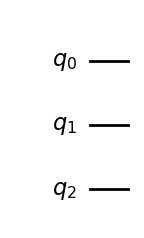

In [15]:
moncircuit = QuantumCircuit(3)
moncircuit.draw(output='mpl')

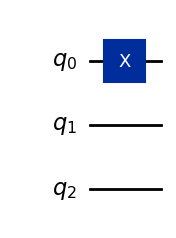

In [3]:
moncircuit.x(0) # ajoute une porte NON sur le qubit q0
moncircuit.draw(output='mpl')  

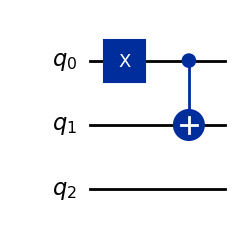

In [4]:
moncircuit.cx(0,1) # ajoute une porte NON contrôlé sur les qubits q0 (contrôle) et q1 (NON)
moncircuit.draw(output='mpl')

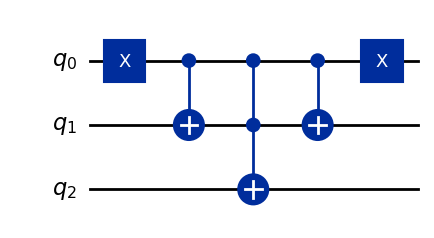

In [5]:
moncircuit.ccx(0,1,2)
# et maintenant on remet les qubits 0 et 1 à leur valeur initiale
moncircuit.cx(0,1)
moncircuit.x(0)
moncircuit.draw(output='mpl')

Voici le code de notre validateur. Il n'est pas nécessaire de comprendre comment il fonctionne pour l'utiliser dans les exercices de la planche.

In [6]:
def validator(ninput, circuit, outset):
    """Teste la fonction classique calculée par le circuit [circuit]
       en considérant que les [ninput] premiers qubits reçoivent une
       entrée binaire et que les autres qubits reçoivent en entrée 0.
       Vérifie que l'ensemble des mesures des qubits en sortie du
       circuit produit l'ensemble de valeurs [outset]."""
    assert circuit.num_clbits == 0
    n = circuit.num_qubits
    nanc = n-ninput
    assert nanc >= 0
    head = QuantumCircuit(n, n)
    for i in range(ninput):
        head.h(i)
    head.barrier()
    tail = QuantumCircuit(n, n)
    tail.barrier()
    for i in range(n):
        tail.measure(i, n-1-i)
    full = head.compose(circuit).compose(tail)
    display(full.draw(output='mpl'))
    res = sim.run(full, shots=65536).result()
    counts = res.get_counts(full)
    display(plot_histogram(counts))
    expset = set(counts.keys())
    return outset == expset

def classicset(ninput, nanc, f):
    rset = set()
    fs = '{:0' + str(ninput) + 'b}'
    ss = '0' * nanc
    for i in range(pow(2,ninput)):
        s = fs.format(i) + ss
        res = f(*map(int,s))
        rset.add(''.join(map(str,res)))
    return rset

Le validateur est appliqué à un circuit en lui indiquant le nombre de bits d'entrée et les sorties attendues lorsque l'entrée parcourt toutes les valeurs. Le validateur affiche le circuit qu'il exécute, le résultats de la simulation et retourne `True` ou `False` selon que le circuit proposé passe ou non le test.

Pour notre circuit d'exemple,

| q0 in | q1 in | q0 out | q1 out | q2 out |
| :-: | :-: | :-: | :-: | :-: |
|0|0|0|0|1|
|0|1|0|1|0|
|1|0|1|0|0|
|1|1|1|1|0|

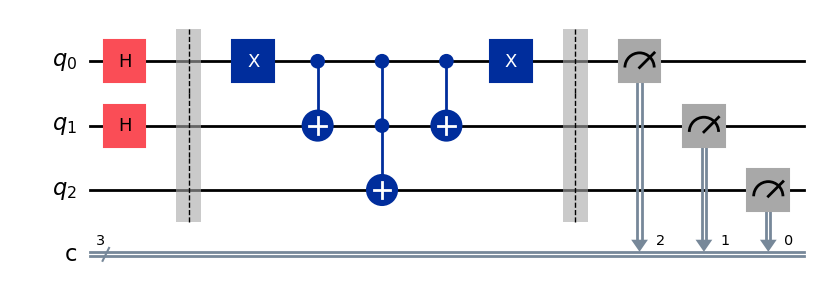

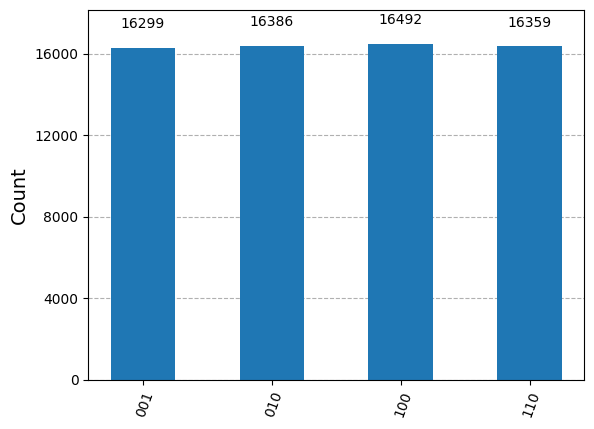

True

In [7]:
validator(2, moncircuit, classicset(2, 1, lambda x,y,z: (x,y,(1-x)*(1-y))))

## 1. Portes logiques classiques

Les circuits booléens classiques sont souvent composés avec les portes NON, ET et OU. À vous de proposer pour chacune des portes ci-dessous une version quantique qui accepte en entrée les bits d'entrée de la porte simulée et produit en sortie ces mêmes bits accompagnés de la valeur calculée par la porte. Nous fournissons le test de validation qui doit retourner `True` pour valider votre solution.

### Porte NON

La porte `NON` inverse la valeur du bit reçu en entrée.

|x|NON(x)|
| :-: | :-: |
|0|1|
|1|0|

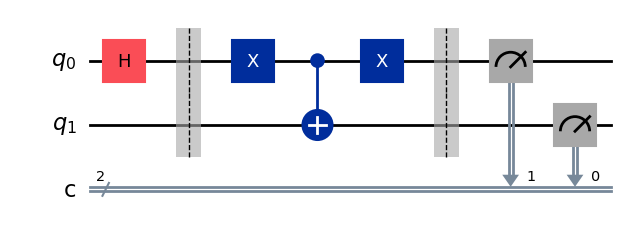

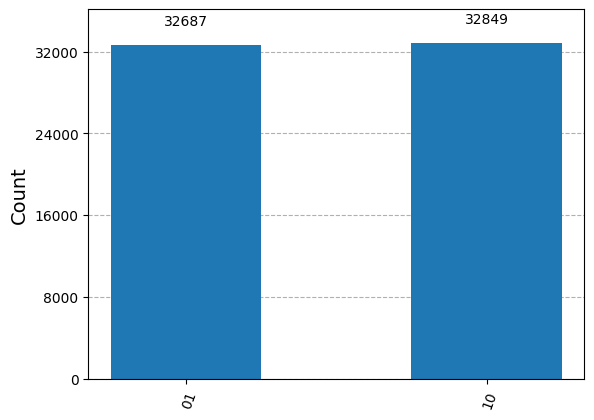

True

In [8]:
circuitNON = QuantumCircuit(2) # un bit d'entrée, un bit de sortie

### AJOUTER ICI CE QU'IL FAUT POUR MODIFIER LE CIRCUIT
### ALLEZ, C'EST LE PREMIER, ON VOUS PROPOSE UNE SOLUTION ;-)
### CE N'EST PAS LA MEILLEURE, VOUS POUVEZ LE FAIRE AVEC UNE PORTE DE MOINS

circuitNON.x(0)
circuitNON.cx(0,1)
circuitNON.x(0)

### ET VOICI LE TEST QUI DOIT RENVOYER TRUE
validator(1, circuitNON, classicset(1,1, lambda x,y: (x,1-x)))

### Porte ET

La porte `ET` teste si les deux bits en entrée sont à 1.

|x|y|ET(x,y)|
| :-: | :-: | :-: |
|0|0|0|
|0|1|0|
|1|0|0|
|1|1|1|

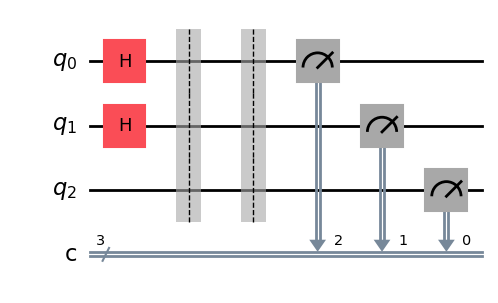

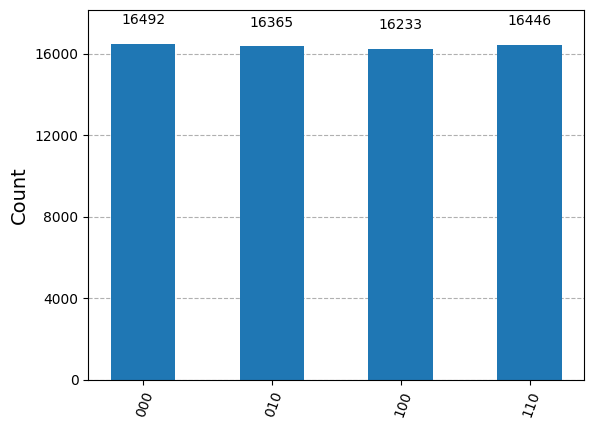

False

In [9]:
circuitET = QuantumCircuit(3) # deux bits d'entrée, un bit de sortie

### AJOUTER ICI CE QU'IL FAUT POUR MODIFIER LE CIRCUIT


### ET VOICI LE TEST QUI DOIT RENVOYER TRUE
validator(2, circuitET, classicset(2,1, lambda x,y,z: (x,y,x*y)))

### Porte OU

La porte `OU` teste si l'un des deux bits en entrée est à 1.

|x|y|OU(x,y)|
| :-: | :-: | :-: |
|0|0|0|
|0|1|1|
|1|0|1|
|1|1|1|

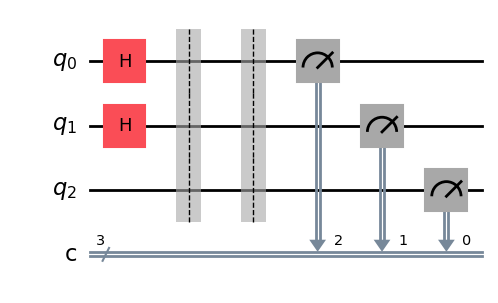

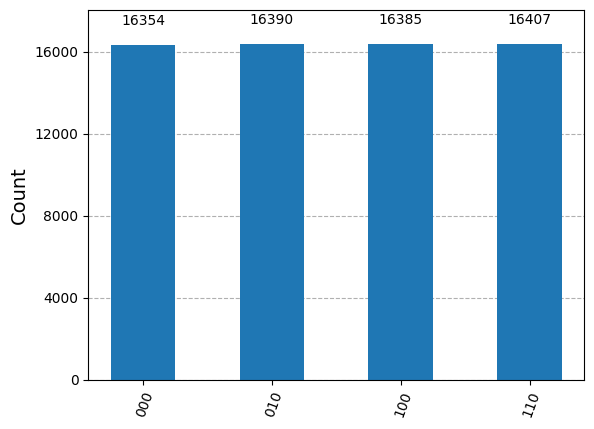

False

In [10]:
circuitOU = QuantumCircuit(3) # deux bits d'entrée, un bit de sortie

### AJOUTER ICI CE QU'IL FAUT POUR MODIFIER LE CIRCUIT



### ET VOICI LE TEST QUI DOIT RENVOYER TRUE
validator(2, circuitOU, classicset(2,1, lambda x,y,z: (x,y,max(x,y))))

### Porte XOR

La porte `XOR` teste si exactement un deux bits en entrée est à 1.

|x|y|XOR(x,y)|
| :-: | :-: | :-: |
|0|0|0|
|0|1|1|
|1|0|1|
|1|1|0|

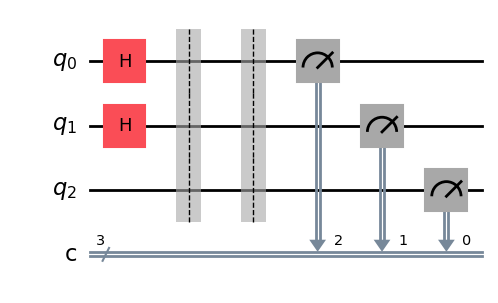

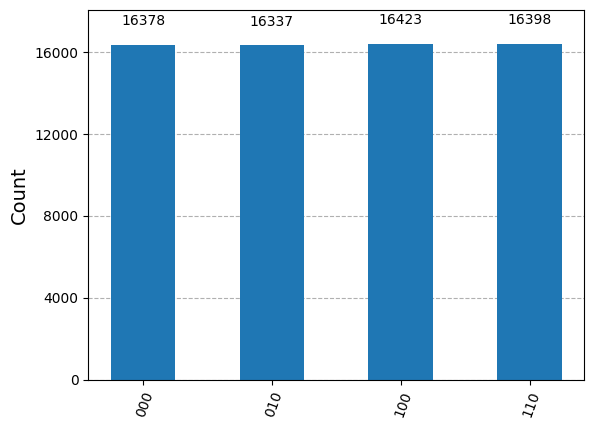

False

In [11]:
circuitXOR = QuantumCircuit(3) # deux bits d'entrée, un bit de sortie

### AJOUTER ICI CE QU'IL FAUT POUR MODIFIER LE CIRCUIT


### ET VOICI LE TEST QUI DOIT RENVOYER TRUE
validator(2, circuitXOR, classicset(2,1, lambda x,y,z: (x,y,x^y)))

## 2. Produit scalaire booléen

Pour l'algorithme de Bernstein-Vazirani étudié dans le cours, nous aurons besoin d'un circuit qui calcule le produit scalaire entre une suite de $k$ bits $x_1, x_2, \ldots, x_k$ fournis en entrée et une chaîne constante $s_1, s_2, \ldots, s_k$ choisie une fois pour toute. Plus précisemment, le circuit attendu prend en entrée les bits $x_1, x_2, \ldots, x_k, y$ et retourne en sortie $x_1, x_2, \ldots, x_k, z$ avec
$$
z = y\oplus\left( x_1\cdot s_1 \oplus x_2\cdot s_2 \oplus \cdots \oplus x_k\cdot s_k\right)
$$

Par exemple, sur 3 bits :
 - si $(s_1,s_2,s_3) = (1,0,1)$ alors $z = y \oplus x_1 \oplus x_3$ ;
 - si $(s_1,s_2,s_3) = (0,0,1)$ alors $z = y \oplus x_3$ ;
 - si $(s_1,s_2,s_3) = (1,1,1)$ alors $z = y \oplus x_1 \oplus x_2 \oplus x_3$.
 
 
 Vous devez écrire une fonction `circuitProduit(s)` qui reçoit en entrée la liste des valeurs $s_1, s_2, \ldots, s_k$ et qui retourne un circuit à $k+1$ qubits qui calcule le produit scalaire entre son entrée et la suite $(s_i)$.

In [12]:
### COMPLETER LA FONCTION circuitProduit POUR QU'ELLE PASSE LES TESTS DE VALIDATION !

def circuitProduit(s):
    k = len(s)
    circuit = QuantumCircuit(k+1)
    ### AJOUTER ICI CE QU'IL FAUT AU CIRCUIT !
    return circuit

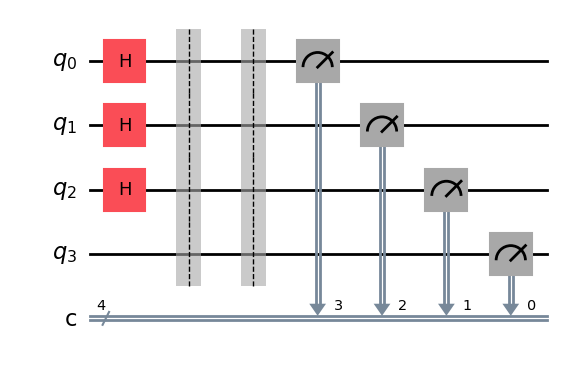

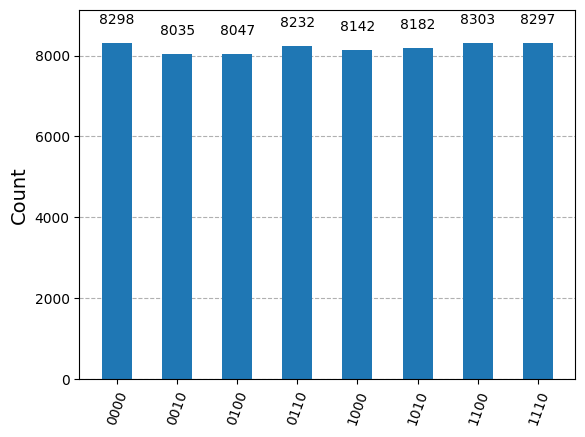

Circuit incorrect pour le vecteur [1, 0, 1]


False

In [13]:
def testscal(s):
    k = len(s)
    def aux(*xs):
        y=xs[k]
        for i in range(k):
            if s[i] == 1:
                y ^= xs[i]
        return [*xs[:-1],y]
    return aux

check = True
for ss in ['101', '00', '001', '111', '10111']:
    s = list(map(int,ss))
    k = len(s)
    circ = circuitProduit(s)
    outset = classicset(k,1,testscal(s))
    check = validator(k, circ, outset)
    if not check:
        print('Circuit incorrect pour le vecteur', s)
        break
check

## 3. Plus ou moins de contrôle

Maintenant que nous avons revu les constructions du cours, passons à quelque chose de plus original. Dans cette partie, nous allons revisiter les constructions de l'article [Elementary gates for quantum computation](https://arxiv.org/pdf/quant-ph/9503016v1) de A. Barenco *et al.* paru dans *Phys.Rev. A52 (1995) 3457*.

La question que nous étudions est la suivante : comment faire pour simuler efficacement une porte NON avec $n$ bits de contrôle, $C^nX$, à l'aide de portes plus simples ? L'efficacité sera mesurée selon deux critères : la profondeur du circuit et le nombre de bits auxiliaires nécessaires au calcul.

### 3.1 Simuler $C^nX$ avec $CCX$

On s'intéresse d'abord au lemme 7.2 situé page 18 de l'article de référence. Il contient une figure que nous reproduisons ici avec qiskit :

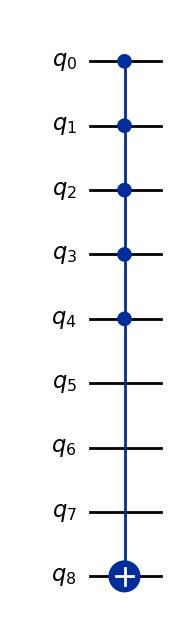

In [21]:
gauche = QuantumCircuit(9)
gauche.mcx([0,1,2,3,4],8)
draw_circ(gauche)

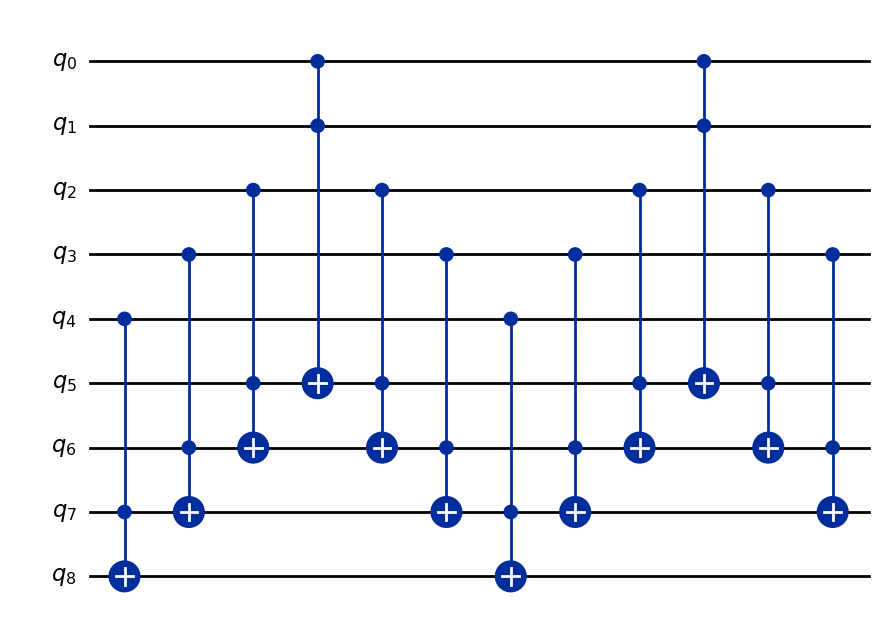

In [31]:
droite = QuantumCircuit(9)
droite.ccx(4,7,8)
droite.ccx(3,6,7)
droite.ccx(2,5,6)
droite.ccx(0,1,5)
droite.ccx(2,5,6)
droite.ccx(3,6,7)
droite.ccx(4,7,8)
droite.ccx(3,6,7)
droite.ccx(2,5,6)
droite.ccx(0,1,5)
droite.ccx(2,5,6)
droite.ccx(3,6,7)
draw_circ(droite)

Demandons à Qiskit de tester si ces deux circuits sont équivalents.

In [32]:
Operator(gauche) == Operator(droite)

True

Dans le texte de l'article, la notation $\Lambda_n(\sigma_x)$ désigne une porte $C^nX$. Lire et comprendre les hypothèses du lemme 7.2. Écrire une fonction qui prend en entrée un nombre $n$ de qubits et un nombre $m$ de bits de contrôle. Cette fonction doit tester si les hypothèses sont satisfaites (si ce n'est pas le cas elle retourne `None`), construire les circuits `gauche` et `droite` correspondant, vérifier que `Operator(gauche) == Operator(droite)` et retourner `droite`.

In [33]:
def first_sim_cnx(n, m):
    "Simule une porte C^m(X) sur un circuit de n qubits"
    pass

### 3.2 Simuler $C^nX$ avec $CCX$ et 1 seul bit auxiliaire

On va maintenant utiliser le lemme 7.3 et le corollaire 7.4 situés page 19 et 20 pour utiliser un unique qubit auxiliaire. Voici la figure de la page 20.

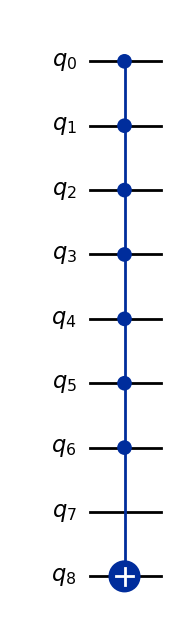

In [36]:
gauche = QuantumCircuit(9)
gauche.mcx([0,1,2,3,4,5,6],8)
draw_circ(gauche)

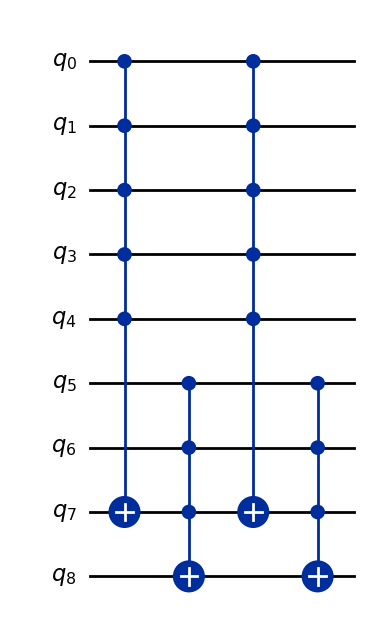

In [37]:
droite = QuantumCircuit(9)
droite.mcx([0,1,2,3,4],7)
droite.mcx([5,6,7],8)
droite.mcx([0,1,2,3,4],7)
droite.mcx([5,6,7],8)
draw_circ(droite)

In [38]:
Operator(gauche) == Operator(droite)

True

Lire et comprendre les hypothèses du lemme 7.3 et du corollaire 7.4. Écrire une fonction qui prend en entrée un nombre $n$ de qubits et un nombre $m$ de bits de contrôle. Cette fonction doit tester si les hypothèses sont satisfaites (si ce n'est pas le cas elle retourne `None`), construire les circuits `gauche` et `droite` correspondant, vérifier que `Operator(gauche) == Operator(droite)` et retourner `droite`.

In [40]:
def second_sim_cnx(n, m):
    "Simule une porte C^m(X) sur un circuit de n qubits en utilisant un unique qubit auxiliaire"
    pass

### 3.3 Ça vous a plu ? Vous en demandez encore ? (BONUS)

Avec des portes quantiques, on peut se débarasser de ce dernier qubit auxiliaire et simuler la port $C^nX$ directement. C'est l'objet des lemmes 7.5 et 7.6 de l'article. Pour cela on a besoin de la porte $\sqrt{X}$, qui vérifie $\sqrt{X} \cdot \sqrt{X} = X$, de son inverse et de leurs versions contrôlées. Elle est notée $SX$ en Quiskit.

Voici un exemple de circuit qui réalise $CX$ grâce à cette astuce :

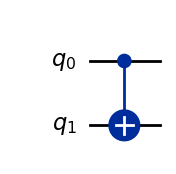

In [41]:
gauche = QuantumCircuit(2)
gauche.cx(0,1)
draw_circ(gauche)

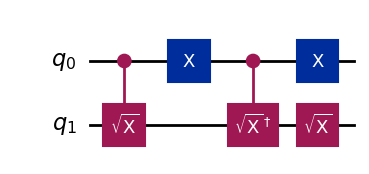

In [45]:
droite = QuantumCircuit(2)
droite.csx(0,1)
droite.x(0)
droite.csx(0,1).inverse()
droite.x(0)
droite.sx(1)
draw_circ(droite)

In [43]:
Operator(gauche) == Operator(droite)

True

Si vous avez besoin de porte contrôlées généralisées, vous pouvez les construire comme ceci (c'est l'exemple de la figure page 21) :

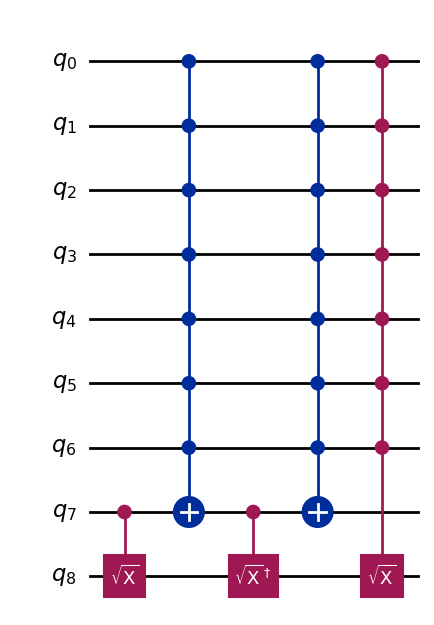

True

In [53]:
from qiskit.circuit.library.standard_gates import SXGate

droite = QuantumCircuit(9)
droite.csx(7,8)
droite.mcx([0,1,2,3,4,5,6],7)
droite.csx(7,8).inverse()
droite.mcx([0,1,2,3,4,5,6],7)
droite.append(SXGate().control(7), (0,1,2,3,4,5,6,8))
draw_circ(droite)

gauche = QuantumCircuit(9)
gauche.mcx([0,1,2,3,4,5,6,7],8)
Operator(gauche) == Operator(droite)

Si vous avez besoin de construire des racines de racines de racines de $X$, vous pouvez les construire comme ceci :

In [1]:
def racine(circ, kieme, qubit):
    "simule une porte racine kieme sur le qubit du circuit circ"
    circ.h(0)
    circ.p(-pi/k, 0)
    circ.h(0)

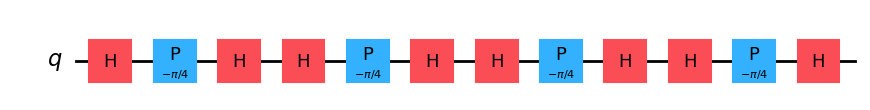

<IPython.core.display.Latex object>

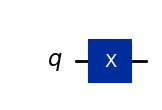

<IPython.core.display.Latex object>

True

In [5]:
from math import pi
moncircuit = QuantumCircuit(1)
k = 1<<2
for _ in range(k):
    racine(moncircuit, k, 0)
show(moncircuit)
moncircuitb = QuantumCircuit(1)
moncircuitb.x(0)
show(moncircuitb)
Operator(moncircuit) == Operator(moncircuitb)

Lire et comprendre les hypothèses du lemme 7.5 et du corollaire 7.6. Écrire une fonction qui prend en entrée un nombre $n$ de qubits. Cette fonction doit construire les circuits `gauche` et `droite` correspondant à la simulation quadratique d'un $C^nX$, vérifier que `Operator(gauche) == Operator(droite)` et retourner `droite`.

In [46]:
def last_sim_cnx(n):
    "Simule une porte C^n(X) sur un circuit de n qubits en utilisant X, SX, CSX et leurs inverses"
    pass

### 3.4 C'est la fin de la fiche ! Vous êtes toujours là ? (BONUS du BONUS)

En TD vous vous êtes intéressés à réaliser la porte $n$-OR qui est un porte OU à $n$ entrées. Montrer qu'on peut simuler cette porte avec $n+1$ qubits ($n$ d'entrée et $1$ de sortie), sans qubit auxiliaire, en utilisant des portes $C^nX$.

In [54]:
def nor_gate(n):
    "Construit un circuit à n+1 qubits qui simule n-OR avec des portes C^nX"
    pass

### 3.5  Il faut sortir de la salle maintenant... On ferme... (BONUS du BONUS du BONUS)

L'article de référence pour cette partie du TP date de 1995. Depuis, de l'eau a coulé sous les ponts. Si vous voulez comment simuler des $C^nX$ de manière plus efficace, nous vous recommandons deux lectures :
 - [Constructing Large Controlled Nots](https://algassert.com/circuits/2015/06/05/Constructing-Large-Controlled-Nots.html), un article de blog en 3 parties de C. Gidney, très pédagogique, sur la simulation avec un nombre linéaires de portes de Toffoli ;
 - [Polylogarithmic-depth controlled-NOT gates without ancilla qubits](https://arxiv.org/pdf/2312.13206) un article de 2024 paru dans *Nature Communications **15**, 5886 (2024)* de B. Claudon *et al.* qui propose une construction encore plus efficace.